In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter


In [3]:
gt_path = 'C:/Users/pioot/train_data/train_gt.csv'
wl_path = 'C:/Users/pioot/train_data/wavelengths.csv'


gt_df = pd.read_csv(gt_path)
wave_lengths = pd.read_csv(wl_path)

In [4]:
#Loading example file, gaining insights about the data

img_no = 1200

path = f'C:/Users/pioot/train_data/train_data/{img_no}.npz'

#axis 0 - band index, 1 - spectral image height, 2 - spectral image width
with np.load(path) as npz:
    spectral_arr = np.ma.MaskedArray(**npz)

bands, height, width = spectral_arr.shape

print(f'Bands = {bands}, height = {height}, width = {width}')
print(f'Data type: {spectral_arr.dtype}')
print(f'Max val = {spectral_arr.max()}, min val = {spectral_arr.min()}')



Bands = 150, height = 107, width = 101
Data type: int16
Max val = 4901, min val = 278


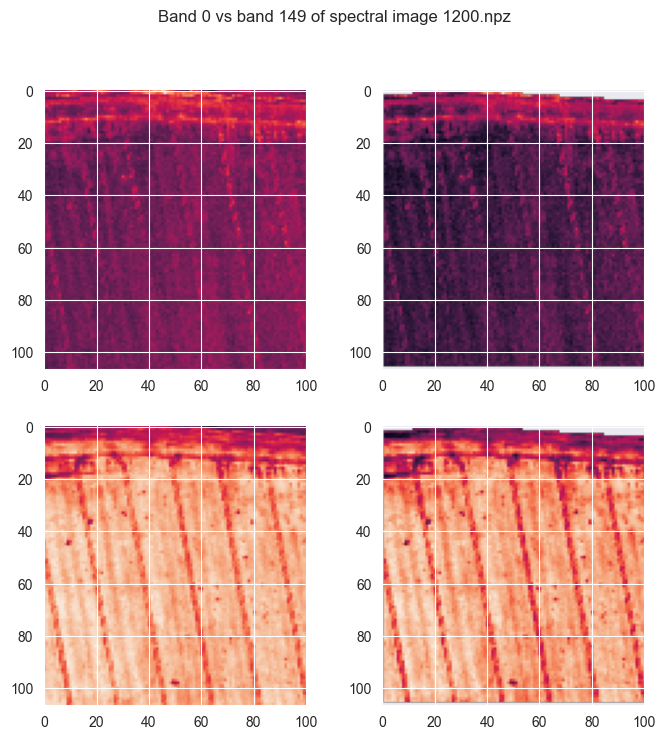

In [5]:
#Plotting with & without binary mask
fig, ax = plt.subplots(2,2, figsize=(8,8))

ax[0,0].imshow(spectral_arr[0,:,:].data)
ax[0,1].imshow(spectral_arr[0,:,:])

ax[1,0].imshow(spectral_arr[149,:,:].data)
ax[1,1].imshow(spectral_arr[149,:,:])

plt.suptitle(f'Band 0 vs band 149 of spectral image {img_no}.npz')
plt.show()

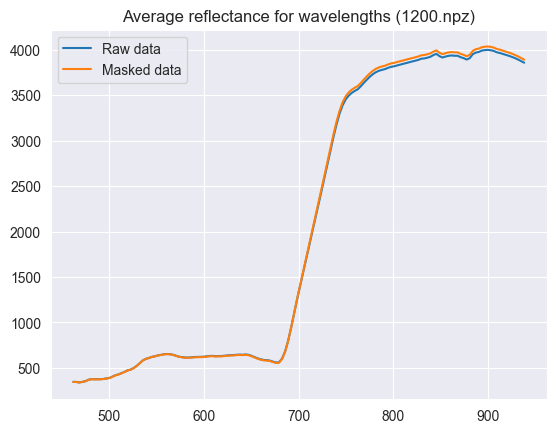

In [6]:
#Plotting spectral reflectance of the example image
spectral_reflectances_masked = [spectral_arr[i,:,:].mean() for i in range(bands)]
spectral_reflectances_raw = [spectral_arr[i,:,:].data.mean() for i in range(bands)]

plt.plot(wave_lengths['wavelength'], spectral_reflectances_raw, label = "Raw data")
plt.plot(wave_lengths['wavelength'], spectral_reflectances_masked, label = "Masked data")
plt.title(f'Average reflectance for wavelengths ({img_no}.npz)')
plt.legend()
plt.show()

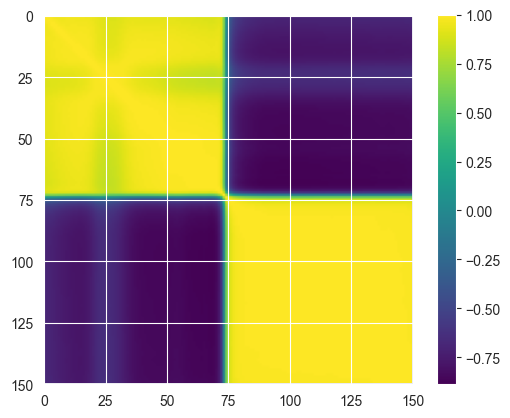

In [7]:
#Calculating correlation between bands of the example image
image_flat = spectral_arr.reshape(bands, -1)
corr = np.corrcoef(image_flat)

plt.imshow(corr, cmap='viridis')
plt.colorbar()
plt.xticks(range(0,bands+1,25))
plt.yticks(range(0,bands+1,25))
plt.show()

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [9]:
#Preparing data for PCA (of the example image)
X = spectral_arr.data.reshape(bands, -1).T #(width * height, bands) transposed

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_transformed = pca.fit_transform(X_scaled)

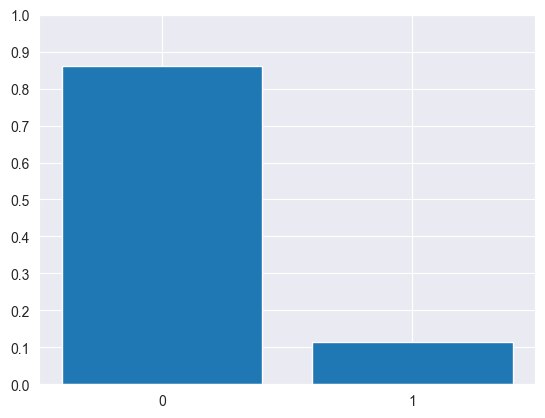

In [10]:
plt.bar(range(pca.n_components_), pca.explained_variance_ratio_)
plt.xticks(range(pca.n_components_))
plt.yticks(np.arange(0,1.1,0.1))
plt.show()

In [11]:
#first principal component
pc1 = pca.components_[0]
pc2 = pca.components_[1]

print(pca.components_.shape)

(2, 150)


In [12]:
    #PCA for almost whole dataset (step = 10 - every 10th image)
X_total = []

for i in range(0,1701,10):
    with np.load(f'C:/Users/pioot/train_data/train_data/{i}.npz') as npz:
        arr = np.ma.MaskedArray(**npz)

    x = arr.data.reshape(arr.shape[0], -1).T #(width * height, bands)
    mask = arr.mask.reshape(arr.shape[0], -1).T

    #including binary mask
    x_valid = x[~mask.any(axis=1)]
    X_total.append(x_valid)

X_total = np.vstack(X_total)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_total)

pca = PCA(n_components=10)
X_transformed = pca.fit_transform(X_scaled)

print(pca.explained_variance_ratio_.cumsum())


[0.67130931 0.9902943  0.99610577 0.99892918 0.9991785  0.99935485
 0.99944833 0.99951335 0.99957001 0.99961949]


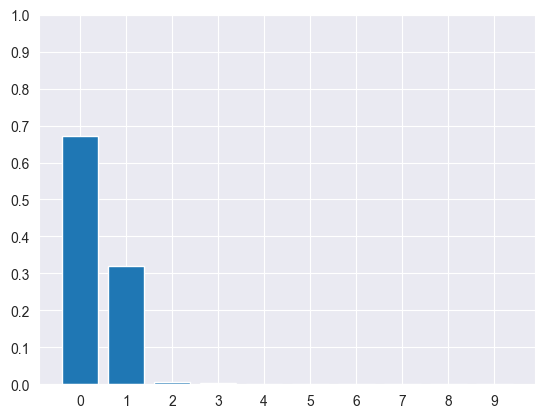

In [13]:
#Plotting variance ratios of every Prinicpal Component - there are 2 PC's that explain >= 95% of the data variance
plt.bar(range(pca.n_components_), pca.explained_variance_ratio_)
plt.xticks(range(pca.n_components_))
plt.yticks(np.arange(0,1.1,0.1))
plt.show()

In [14]:
def plot_pca_loadings(pca_model, wavelengths=None, n_components=3):
    """
    Visualizes PCA loadings (eigenvectors) to show band influence.
    """
    loadings = pca_model.components_

    n_bands = loadings.shape[1]

    if wavelengths is None:
        x_axis = np.arange(n_bands)
        x_label = "Band Index"
    else:
        if len(wavelengths) != n_bands:
            print(f"WARNING: Length of wavelengths list ({len(wavelengths)}) does not match number of bands in PCA ({n_bands}). Using indices.")
            x_axis = np.arange(n_bands)
            x_label = "Band Index"
        else:
            x_axis = wavelengths
            x_label = "Wavelength [nm]"

    plt.figure(figsize=(14, 6))

    colors = ['blue', 'orange', 'green', 'red', 'purple']

    for i in range(n_components):
        c = colors[i % len(colors)]
        plt.plot(x_axis, loadings[i, :], label=f'PC {i+1}', color=c, linewidth=1.5)

        max_idx = np.argmax(np.abs(loadings[i, :]))
        plt.scatter(x_axis[max_idx], loadings[i, max_idx], color=c, s=50, zorder=5)

    plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)

    plt.title(f'PCA Loadings: Band Influence on First {n_components} Components', fontsize=14)
    plt.xlabel(x_label, fontsize=12)
    plt.ylabel('Loading Value (Eigenvector Coefficient)', fontsize=12)
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

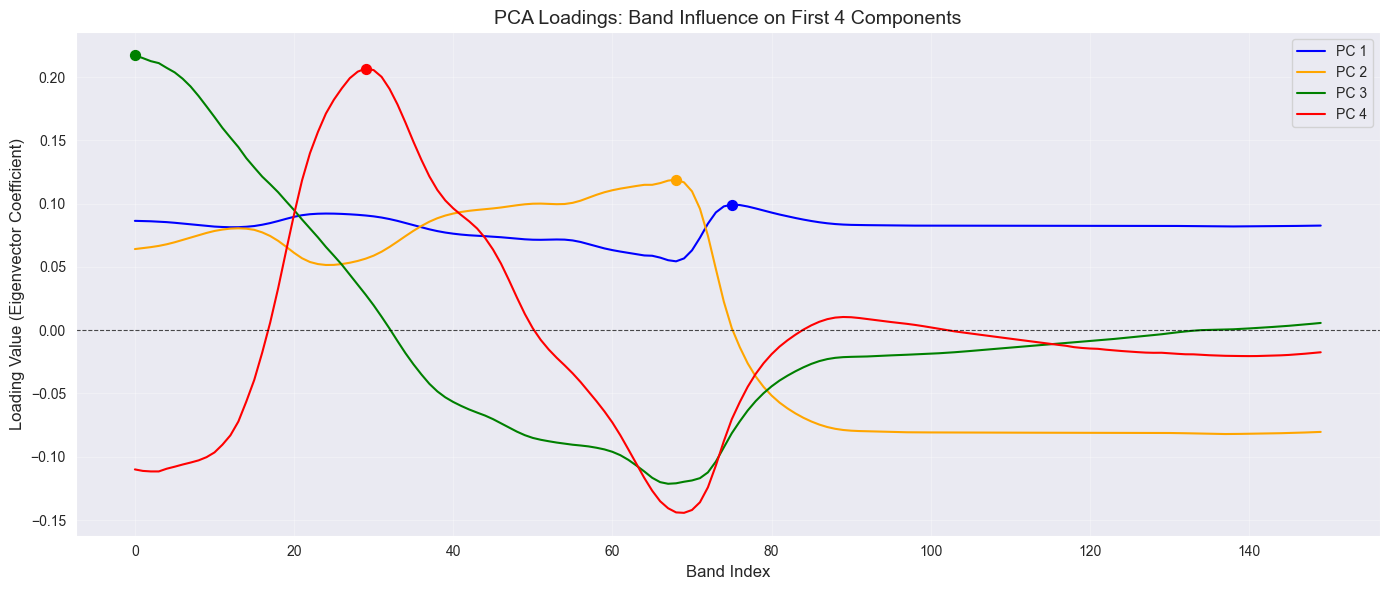

In [15]:
plot_pca_loadings(pca, wavelengths=None, n_components=4)

Calculating avarage spectrum for each image

In [16]:
X_means = []
valid_indices = []


for idx, row in gt_df.iterrows():
    img_id = int(row.get('sample_index', idx))

    path = f'C:/Users/pioot/train_data/train_data/{img_id}.npz'

    try:
        with np.load(path) as npz:
            arr = np.ma.MaskedArray(**npz)
        mean_spectrum = arr.mean(axis=(1,2))
        if np.ma.is_masked(mean_spectrum):
            continue
        X_means.append(mean_spectrum.data)
        valid_indices.append(idx)

    except FileNotFoundError:
        print(f"File not found for index {img_id}")
        continue

X_means = np.array(X_means)
gt_df_clean = gt_df.loc[valid_indices].reset_index(drop=True)
print({X_means.shape})
print( {len(gt_df_clean)})

{(1732, 150)}
{1732}


In [17]:
target_cols = ['P', 'K', 'Mg', 'pH']
if 'wave_lengths' in locals():
    wl_axis = wave_lengths['wavelength'].values
    index_name = 'Wavelength [nm]'
else:
    wl_axis = np.arange(X_means.shape[1])
    index_name = 'Band Index'
correlations = {col: [] for col in target_cols}
for band_idx in range(X_means.shape[1]):
    band_vals = X_means[:, band_idx]

    for target in target_cols:
        if target not in gt_df_clean.columns:
            continue

        y_vals = gt_df_clean[target].values
        if np.std(band_vals) == 0 or np.std(y_vals) == 0:
            corr = 0 #
        else:
            corr, _ = spearmanr(band_vals, y_vals)
        correlations[target].append(corr)


In [18]:
feature_corr_matrix = gt_df_clean[target_cols].corr(method='spearman')
print(feature_corr_matrix)

           P         K        Mg        pH
P   1.000000  0.380047 -0.146342  0.137364
K   0.380047  1.000000  0.252113  0.128206
Mg -0.146342  0.252113  1.000000 -0.013374
pH  0.137364  0.128206 -0.013374  1.000000


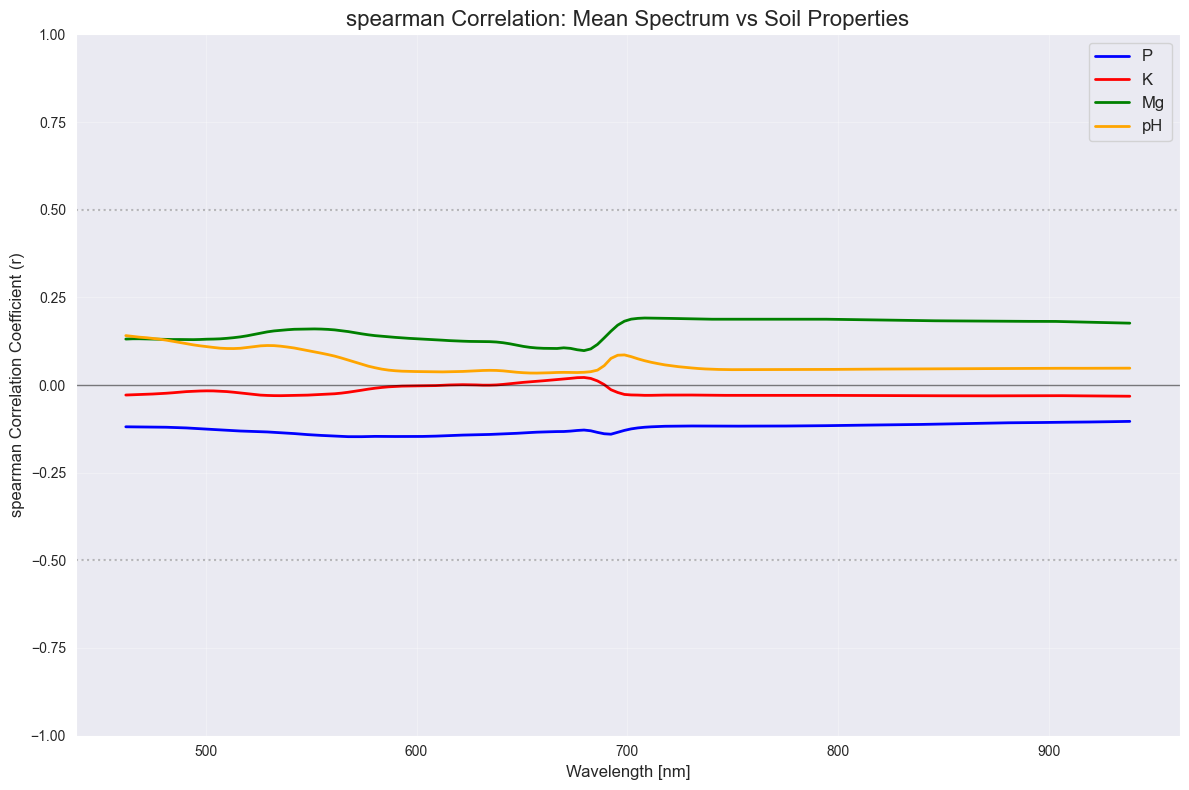

In [19]:
plt.figure(figsize=(12, 8))

colors = ['blue', 'red', 'green', 'orange', 'purple', 'brown']

for i, target in enumerate(target_cols):
    if target in correlations and len(correlations[target]) > 0:


        current_color = colors[i % len(colors)]

        plt.plot(wl_axis, correlations[target], label=target, color=current_color, linewidth=2)

plt.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.5)
plt.axhline(0.5, color='gray', linestyle=':', alpha=0.5)
plt.axhline(-0.5, color='gray', linestyle=':', alpha=0.5)

plt.title('spearman Correlation: Mean Spectrum vs Soil Properties', fontsize=16)
plt.xlabel('Wavelength [nm]', fontsize=12)
plt.ylabel('spearman Correlation Coefficient (r)', fontsize=12)
plt.legend(fontsize=12, loc='upper right')
plt.grid(True, alpha=0.3)

plt.ylim(-1.0, 1.0)
plt.tight_layout()
plt.show()

In [60]:
def preprocess_dataset_with_gauss_sg(gt_df, data_dir, target_cols=['P', 'K', 'Mg', 'pH']):
        X_features = []
        y_labels = []
        valid_indices = []
        sigma_params = (0, 2, 2)
        sg_window = 11
        sg_poly = 2
        sg_deriv = 1

        print(f"Method: Gauss(sigma={sigma_params}) -> Mean -> SavGol(deriv={sg_deriv})")
        for i, row in gt_df.iterrows():
            img_id = int(row.get('sample_index', i))
            path = f'{data_dir}/{img_id}.npz'

            try:
                with np.load(path) as npz:
                    spectral_arr = np.ma.MaskedArray(**npz)


                spectral_arr_gauss = spectral_arr.copy()
                blurred_data = gaussian_filter(spectral_arr.data, sigma=sigma_params)
                spectral_arr_gauss.data[:] = blurred_data

                mean_spectrum = spectral_arr_gauss.mean(axis=(1, 2))
                if np.ma.is_masked(mean_spectrum):
                    continue
                mean_spectrum_data = mean_spectrum.data

                derivative_sg = savgol_filter(mean_spectrum_data, window_length=sg_window, polyorder=sg_poly, deriv=sg_deriv)



                X_features.append(derivative_sg)
                y_labels.append(row[target_cols].values)
                valid_indices.append(img_id)
            except Exception as e:
                print(f"Error {img_id}: {e}")
                continue
            if i > 0 and i % 100 == 0:
                print(f"   Processed {i} / {len(gt_df)}...")
        X = np.array(X_features)
        y = np.array(y_labels)

        print(X.shape)
        return X, y, valid_indices

data_folder = 'C:/Users/pioot/train_data/train_data'
X_processed, y_all, indices = preprocess_dataset_with_gauss_sg(gt_df, data_folder)

Method: Gauss(sigma=(0, 2, 2)) -> Mean -> SavGol(deriv=1)
   Processed 100 / 1732...
   Processed 200 / 1732...
   Processed 300 / 1732...
   Processed 400 / 1732...
   Processed 500 / 1732...
   Processed 600 / 1732...
   Processed 700 / 1732...
   Processed 800 / 1732...
   Processed 900 / 1732...
   Processed 1000 / 1732...
   Processed 1100 / 1732...
   Processed 1200 / 1732...
   Processed 1300 / 1732...
   Processed 1400 / 1732...
   Processed 1500 / 1732...
   Processed 1600 / 1732...
   Processed 1700 / 1732...
(1732, 150)


In [62]:
def rfe_selection(X, y, n_features_to_select=50, step=5):
    estimator = RandomForestRegressor(
        n_estimators=100,
        n_jobs=-1,
        random_state=42
    )
    selector = RFE(
        estimator=estimator,
        n_features_to_select=n_features_to_select,
        step=step,
        verbose=1
    )

    selector.fit(X, y)

    X_selected = selector.transform(X)
    mask = selector.get_support()
    selected_indices = np.where(mask)[0]

    print(X_selected.shape)

    return X_selected, selected_indices, selector

In [63]:
N_FEATURES = 50
STEP_SIZE = 5

X_rfe, rfe_indices, rfe_model = rfe_selection(
    X_processed,
    y_all,
    n_features_to_select=N_FEATURES,
    step=STEP_SIZE
)

rfe_indices.sort()
print(f"\nIndices of selected bands:\n{rfe_indices}")

Fitting estimator with 150 features.
Fitting estimator with 145 features.
Fitting estimator with 140 features.
Fitting estimator with 135 features.
Fitting estimator with 130 features.
Fitting estimator with 125 features.
Fitting estimator with 120 features.
Fitting estimator with 115 features.
Fitting estimator with 110 features.
Fitting estimator with 105 features.
Fitting estimator with 100 features.
Fitting estimator with 95 features.
Fitting estimator with 90 features.
Fitting estimator with 85 features.
Fitting estimator with 80 features.
Fitting estimator with 75 features.
Fitting estimator with 70 features.
Fitting estimator with 65 features.
Fitting estimator with 60 features.
Fitting estimator with 55 features.
(1732, 50)

Indices of selected bands:
[  0   2   5  11  13  18  24  27  30  35  41  44  49  51  53  57  58  59
  64  65  66  67  68  69  71  74  87  89  93  94  98 101 104 109 117 120
 122 124 125 128 129 130 134 135 136 137 138 140 142 149]
